# Lab 1

Developing neural nets with Keras framework  
By Alex Horyshevskyi  

### Installing dependencies

In [12]:
%pip install pandas pyarrow matplotlib seaborn tensorflow[and-cuda] tqdm scikit-learn kagglehub --quiet

Note: you may need to restart the kernel to use updated packages.


### TensorFlow GPU availability check

In [13]:
import tensorflow as tf


gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Found: {len(gpus)}\n{gpus}")

# Faster runtime bc VRAM is allocated on demand
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Faster precision for GPU compute
if gpus:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision policy:", tf.keras.mixed_precision.global_policy())


GPUs Found: 1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">


### Define constants

In [14]:
from typing import Literal
from os import path


BATCH_SIZE = 64

ModelMode = Literal["regression", "classification"]

Splits = Literal["train", "validation", "test"]
splits: dict[Splits, float] = {"train": 0.7, "validation": 0.2, "test": 0.1}

activations = ["relu", "tanh", "sigmoid"]

metrics_to_measure = {
    "regression": [
        "mean_squared_error",
        "mean_absolute_error",
        "mean_absolute_percentage_error",
    ],
    "classification": [
        "accuracy",
        "precision",
        "recall",
        "AUC",
        "bce",
        "kl_divergence",
        "poisson",
    ],
}

workdir = "./"
hourly_wages_path = path.join(workdir, "hourly_wages_data.csv")
diabetes_path = path.join(workdir, "diabetes_data.csv")

### Import the datasets

In [15]:
import pandas as pd


hourly_wages_df = pd.read_csv(hourly_wages_path, engine='pyarrow')
hourly_wages_df.head()

,wage_per_hour,union,education_yrs,experience_yrs,age,female,marr,south,manufacturing,construction
0,5.10,0,8,21,35,1,1,0,1,0
1,4.95,0,9,42,57,1,1,0,1,0
2,6.67,0,12,1,19,0,0,0,1,0
3,4.00,0,12,4,22,0,0,0,0,0
4,7.50,0,12,17,35,0,1,0,0,0


In [16]:
import pandas as pd


diabetes_df = pd.read_csv(diabetes_path, engine='pyarrow')
diabetes_df.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [17]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("amar5693/student-performance-dataset")

print("Path to dataset files:", path)

productivity_df = pd.read_csv(path + "/ultimate_student_productivity_dataset_5000.csv", engine='pyarrow')
productivity_df = productivity_df.drop(columns=["student_id", "exam_score"])
productivity_df.head()

Path to dataset files: /home/rojikaru/.cache/kagglehub/datasets/amar5693/student-performance-dataset/versions/1


,age,gender,academic_level,study_hours,self_study_hours,online_classes_hours,social_media_hours,gaming_hours,sleep_hours,screen_time_hours,exercise_minutes,caffeine_intake_mg,part_time_job,upcoming_deadline,internet_quality,mental_health_score,focus_index,burnout_level,productivity_score
0,18,Other,High School,7.64,1.56,2.20,3.05,2.19,6.52,6.47,81,38,1,0,Good,10,43.05,31.77,73.65
1,18,Other,High School,2.21,2.22,2.10,1.65,2.55,5.97,6.05,111,339,0,0,Good,3,15.92,37.00,13.70
2,22,Male,High School,3.45,0.00,0.29,1.34,2.08,8.39,7.62,68,266,0,1,Good,8,27.39,34.37,45.15
3,17,Other,High School,5.75,2.08,3.01,2.27,2.20,6.31,11.67,113,480,1,1,Poor,3,22.31,77.31,20.92
4,19,Other,High School,6.83,1.72,3.33,2.65,0.70,8.01,10.02,121,24,1,0,Good,8,38.11,39.53,59.23


### Data preprocessing

In [18]:
import pandas as pd


def preprocess_data(df: pd.DataFrame) -> pd.DataFrame:
    # Handle missing values
    df = df.dropna()

    # Detect categorical variables (object or category dtype) and numerical variables (int64 or float64 dtype)
    categorical_cols = df.select_dtypes(include=["object", "category"]).columns
    categorical_cols = [col for col in categorical_cols if df[col].nunique() < 10]

    # Encode categorical variables if any
    df = pd.get_dummies(df, drop_first=True, columns=categorical_cols)

    numerical_cols = df.select_dtypes(include=["float64", "int64"]).columns
    dummy_cols = [col for col in df.columns if df[col].dtype != float and df[col].nunique() == 2]
    numerical_cols = [col for col in numerical_cols if col not in dummy_cols]

    # Handle outliers using IQR method
    coef = 1.5
    for col in numerical_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - coef * IQR
        upper_bound = Q3 + coef * IQR
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    # Drop zero-variance columns — IQR filtering can reduce a column to a constant,
    # causing division by zero in StandardScaler
    zero_var_cols = [col for col in numerical_cols if df[col].std() == 0]
    if zero_var_cols:
        print(f"Dropping zero-variance columns: {zero_var_cols}")
        df = df.drop(columns=zero_var_cols)

    return df

### Split the datasets

In [19]:
from sklearn.model_selection import train_test_split


def split_and_scale(
    df: pd.DataFrame,
    splits: dict[Splits, float],
    target_col: str,
    random_state: int = 42,
) -> dict[Splits, tuple[pd.DataFrame, pd.Series]]:
    splitted_and_scaled = {}

    # Shuffle the DataFrame
    shuffled_df = df.sample(frac=1, random_state=random_state).reset_index(drop=True)

    # Split the DataFrame into train, validation and test sets using sklearn
    X = shuffled_df.drop(columns=[target_col])
    y = shuffled_df[target_col].reset_index(drop=True)

    # Balance the dataset using undersampling
    # if it's a classification task with imbalanced classes
    if y.nunique() == 2:
        class_counts = y.value_counts()
        if class_counts.min() / class_counts.max() < 0.5:
            print("Balancing the dataset using undersampling...")
            minority_class = class_counts.idxmin()
            majority_class = class_counts.idxmax()
            minority_df = shuffled_df[shuffled_df[target_col] == minority_class]
            majority_df = shuffled_df[shuffled_df[target_col] == majority_class].sample(
                n=class_counts.min(), random_state=random_state
            )
            balanced_df = (
                pd.concat([minority_df, majority_df])
                .sample(frac=1, random_state=random_state)
                .reset_index(drop=True)
            )
            X = balanced_df.drop(columns=[target_col])
            y = balanced_df[target_col].reset_index(drop=True)

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=splits["validation"] + splits["test"],
        random_state=random_state,
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=splits["test"] / (splits["validation"] + splits["test"]),
        random_state=random_state,
    )

    splitted_and_scaled["train"] = (X_train, y_train)
    splitted_and_scaled["validation"] = (X_val, y_val)
    splitted_and_scaled["test"] = (X_test, y_test)

    return splitted_and_scaled

### Build a model

In [20]:
from keras.models import Sequential
from keras.layers import BatchNormalization, Dense, Dropout, Input


def build_model(
    input_shape: int, 
    mode: ModelMode, 
    optimizer: str, 
    activation: str,
    steps_per_execution: int = 1,
) -> Sequential:
    """
    Builds a simple feedforward neural network model.

    :param input_shape: The number of features in the input data.
    :param mode: The type of model to build ('regression' or 'classification').
    :param optimizer: The optimizer to use for compiling the model.
    :param activation: The activation function to use in the hidden layers.
    :param steps_per_execution: Number of batches to run per tf.function call.
                                Set to steps_per_epoch to eliminate all Python overhead.
    :return: A compiled Keras Sequential model.
    """

    if mode == "classification":
        final_activation = "sigmoid"
        loss = "binary_crossentropy"
    else:
        final_activation = None
        loss = "mean_squared_error"

    model = Sequential(
        [
            Input(shape=(input_shape,)),
            Dense(64, activation=activation),
            Dropout(0.3),
            BatchNormalization(),
            Dense(32, activation=activation),
            Dense(16, activation=activation),
            # dtype=float32 on the output layer is required for mixed-precision stability
            Dense(1, activation=final_activation, dtype="float32"),
        ]
    )
    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=metrics_to_measure[mode],
        steps_per_execution=steps_per_execution,

        # XLA-compile the train step → fuses ops, reduces kernel launches
        jit_compile=True
    )
    return model


### Define the pipeline

In [21]:
from typing import Mapping, Any
from math import ceil
import random

import tensorflow as tf
from keras.callbacks import EarlyStopping
from keras.optimizers import Optimizer, RMSprop, Adam, Adadelta, Adagrad, Adamax, Nadam

import numpy as np
import pandas as pd
from tqdm import tqdm


def _make_tf_dataset(
    x: pd.DataFrame, y: pd.Series, batch_size: int, shuffle: bool = False
) -> tf.data.Dataset:
    """Convert a DataFrame split into a prefetched tf.data.Dataset."""
    ds = tf.data.Dataset.from_tensor_slices(
        (
            x.values.astype("float32"),
            # (N,) → (N, 1) to match model output shape
            y.values.astype("float32").reshape(-1, 1),
        )
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=len(x), reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def build_optimizers() -> list[str | Optimizer]:
    return [
        "sgd",
        RMSprop(
            learning_rate=0.001, rho=0.9, momentum=0.0, epsilon=1e-07, name="RMSprop"
        ),
        Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07, name="Adam"),
        Adadelta(learning_rate=0.001, rho=0.95, epsilon=1e-07, name="Adadelta"),
        Adagrad(
            learning_rate=0.001,
            initial_accumulator_value=0.1,
            epsilon=1e-07,
            name="Adagrad",
        ),
        Adamax(
            learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07, name="Adamax"
        ),
        Nadam(
            learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07, name="Nadam"
        ),
    ]


def build_models(
    mode: ModelMode,
    input_shape: int,
    activations: list[str],
    steps_per_execution: int = 1,
) -> dict[tuple[str, str], Sequential]:
    models = {}
    for activation in (pbar := tqdm(activations, desc="Building models")):
        pbar.set_postfix({"activation": activation})
        for optimizer in build_optimizers():
            optimizer_name = optimizer if isinstance(optimizer, str) else optimizer.name
            pbar.set_postfix({"optimizer": optimizer_name, "activation": activation})
            models[(optimizer_name, activation)] = build_model(
                input_shape=input_shape,
                mode=mode,
                optimizer=optimizer,
                activation=activation,
                steps_per_execution=steps_per_execution,
            )
    return models


def train_models(
    models: dict[tuple[str, str], Sequential],
    splitted_df: dict[Splits, tuple[pd.DataFrame, pd.Series]],
    epochs: int,
    early_stop_patience: int,
) -> dict[tuple[str, str], Mapping[str, list[float]]]:
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=early_stop_patience,
        restore_best_weights=True,
    )
    callbacks = [early_stopping]

    # Build tf.data datasets once — reused across all models
    train_x, train_y = splitted_df["train"]
    val_x, val_y = splitted_df["validation"]
    train_ds = _make_tf_dataset(train_x, train_y, BATCH_SIZE, shuffle=True)
    val_ds = _make_tf_dataset(val_x, val_y, BATCH_SIZE, shuffle=False)

    histories: dict[tuple[str, str], Mapping[str, list[float]]] = {}

    for (optimizer, activation), model in (
        pbar := tqdm(models.items(), desc="Training models")
    ):
        pbar.set_postfix({"optimizer": optimizer, "activation": activation})

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            callbacks=callbacks,
            verbose=0,
        )
        histories[(optimizer, activation)] = history.history

    return histories


def eval_models(
    models: dict[tuple[str | Optimizer, str], Sequential],
    splitted_df: dict[Splits, tuple[pd.DataFrame, pd.Series]],
    mode: ModelMode,
):
    results = {}
    test_x, test_y = splitted_df["test"]
    test_ds = _make_tf_dataset(test_x, test_y, BATCH_SIZE)

    for (optimizer, activation), model in (
        pbar := tqdm(models.items(), desc="Evaluating models")
    ):
        optimizer_name = optimizer if isinstance(optimizer, str) else optimizer.name
        pbar.set_postfix({"optimizer": optimizer_name, "activation": activation})

        test_loss, *test_metrics = model.evaluate(test_ds, verbose=0)

        results[(optimizer_name, activation)] = {
            "loss": test_loss,
            "metrics": dict(zip(metrics_to_measure[mode], test_metrics)),
        }
    return (results, mode)


def pipeline(
    target_df: pd.DataFrame,
    target_column: str,
    activations: list[str],
    name: str | None = None,
    mode: ModelMode | None = None,
    random_seed: int = 67,
):
    """
    Run the full pipeline of splitting the dataset, building, training and evaluating models.

    :param target_df: The DataFrame containing the dataset.
    :param target_column: The name of the target column in the DataFrame.
    :param activations: A list of activation function names to use for building the models.
    :param name: An optional name for the dataset, used for printing progress messages.
    :param mode: The type of model to build ('regression' or 'classification').
    :param random_seed: The random seed for reproducibility (default is 42).
    :return: A tuple with evaluation results, mode, and training history per model.
    """

    if name:
        print(f"Running the pipeline for {name} dataset...")

    if mode is None:
        mode = (
            "classification"
            if target_df[target_column].nunique() <= 2
            else "regression"
        )

    # Seed everything to make the entire pipeline deterministic and reproducible
    random.seed(random_seed)
    np.random.seed(random_seed)
    tf.random.set_seed(random_seed)

    prepared_df = preprocess_data(target_df)
    splitted_df = split_and_scale(prepared_df, splits, target_column, random_seed)

    train_x, _ = splitted_df["train"]
    input_shape = train_x.shape[1]

    steps_per_epoch = max(1, ceil(len(train_x) / BATCH_SIZE))
    print(f"steps_per_epoch={steps_per_epoch}")

    models = build_models(mode, input_shape, activations, steps_per_epoch)
    histories = train_models(models, splitted_df, epochs=300, early_stop_patience=15)
    eval_results, eval_mode = eval_models(models, splitted_df, mode)
    return (eval_results, eval_mode, histories)

### Plot the stats

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_metrics(
        results: dict[tuple[str, str], Mapping[str, Any]], 
        mode: ModelMode
    ):
    """
    Plots the metrics for the different model configurations.

    :param results: A dictionary with the model configurations as keys and their evaluation results as values.
    :param mode: The type of model ('regression' or 'classification') to determine which metrics to plot.
    """

    print(f"Plotting metrics for {mode} dataset...")
    metrics_to_plot = metrics_to_measure[mode]

    data = {}
    for (optimizer, activation), result in results.items():
        for metric_name in metrics_to_plot:
            if metric_name not in data:
                data[metric_name] = []
            data[metric_name].append({
                "optimizer": optimizer,
                "activation": activation,
                "metric": metric_name,
                "value": result["metrics"][metric_name]
            })

    fig, ax = plt.subplots(len(metrics_to_plot), 1, figsize=(6, 18))
    for i, metric_name in enumerate(metrics_to_plot):
        df = pd.DataFrame(data[metric_name])
        sns.barplot(x="optimizer", y="value", hue="activation", data=df, ax=ax[i])
        ax[i].set_title(f"{metric_name} for {mode}")
        ax[i].legend(title="Activation")

    plt.tight_layout()
    plt.show()


def plot_loss_curves(
        histories: dict[tuple[str, str], Mapping[str, list[float]]],
        title: str
    ):
    records: list[dict[str, Any]] = []
    for (optimizer, activation), history in histories.items():
        losses = history.get("loss", [])
        val_losses = history.get("val_loss", [])

        for idx, value in enumerate(losses, start=1):
            records.append({
                "epoch": idx,
                "loss": value,
                "split": "train",
                "optimizer": optimizer,
                "activation": activation,
            })

        for idx, value in enumerate(val_losses, start=1):
            records.append({
                "epoch": idx,
                "loss": value,
                "split": "validation",
                "optimizer": optimizer,
                "activation": activation,
            })

    if not records:
        print("No loss history found to plot.")
        return

    df = pd.DataFrame(records)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
    for split, ax in zip(["train", "validation"], axes):
        split_df = df[df["split"] == split]
        if split_df.empty:
            ax.set_visible(False)
            continue
        sns.lineplot(
            data=split_df,
            x="epoch",
            y="loss",
            hue="optimizer",
            style="activation",
            ax=ax,
        )
        ax.set_title(f"{title} - {split} loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend(title="Optimizer / Activation")

    plt.tight_layout()
    plt.show()

### Run the pipeline

Running the pipeline for Hourly Wages Dataset dataset...
steps_per_epoch=5


Building models:   0%|          | 0/3 [00:00<?, ?it/s, optimizer=sgd, activation=relu]

Evaluating models: 100%|██████████| 21/21 [00:07<00:00,  2.86it/s, optimizer=Nadam, activation=sigmoid]   


Plotting metrics for regression dataset...


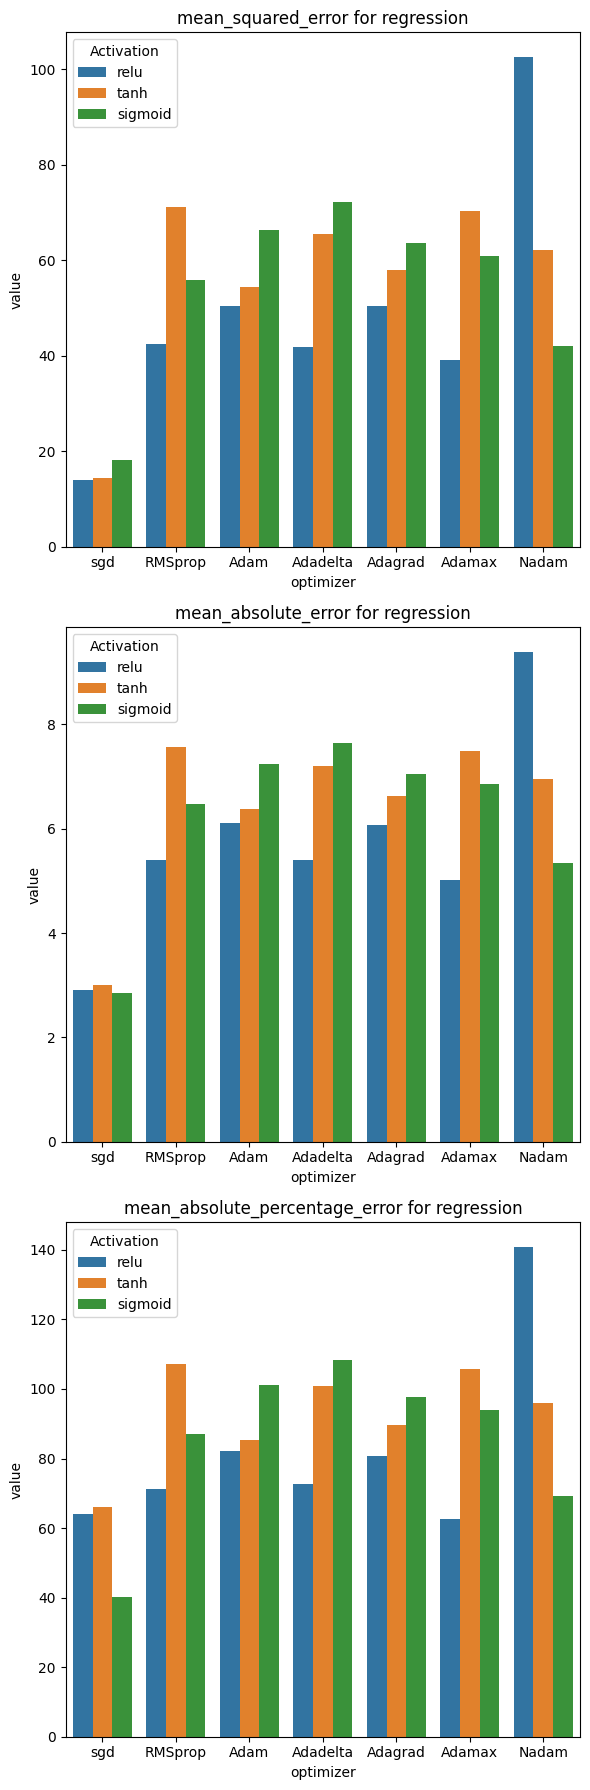

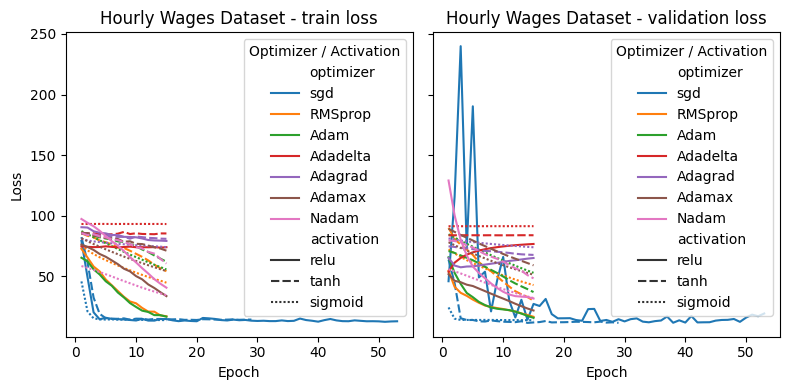

In [23]:
hourly_wages_title = "Hourly Wages Dataset"
hourly_wages_metrics, hourly_wages_mode, hourly_wages_history = pipeline(
    hourly_wages_df,
    target_column='wage_per_hour', 
    activations=activations,
    name=hourly_wages_title,
)

plot_metrics(hourly_wages_metrics, hourly_wages_mode)
plot_loss_curves(hourly_wages_history, hourly_wages_title)

Running the pipeline for Diabetes Dataset dataset...
Balancing the dataset using undersampling...
steps_per_epoch=5


Evaluating models: 100%|██████████| 21/21 [00:13<00:00,  1.58it/s, optimizer=Nadam, activation=sigmoid]   


Plotting metrics for classification dataset...


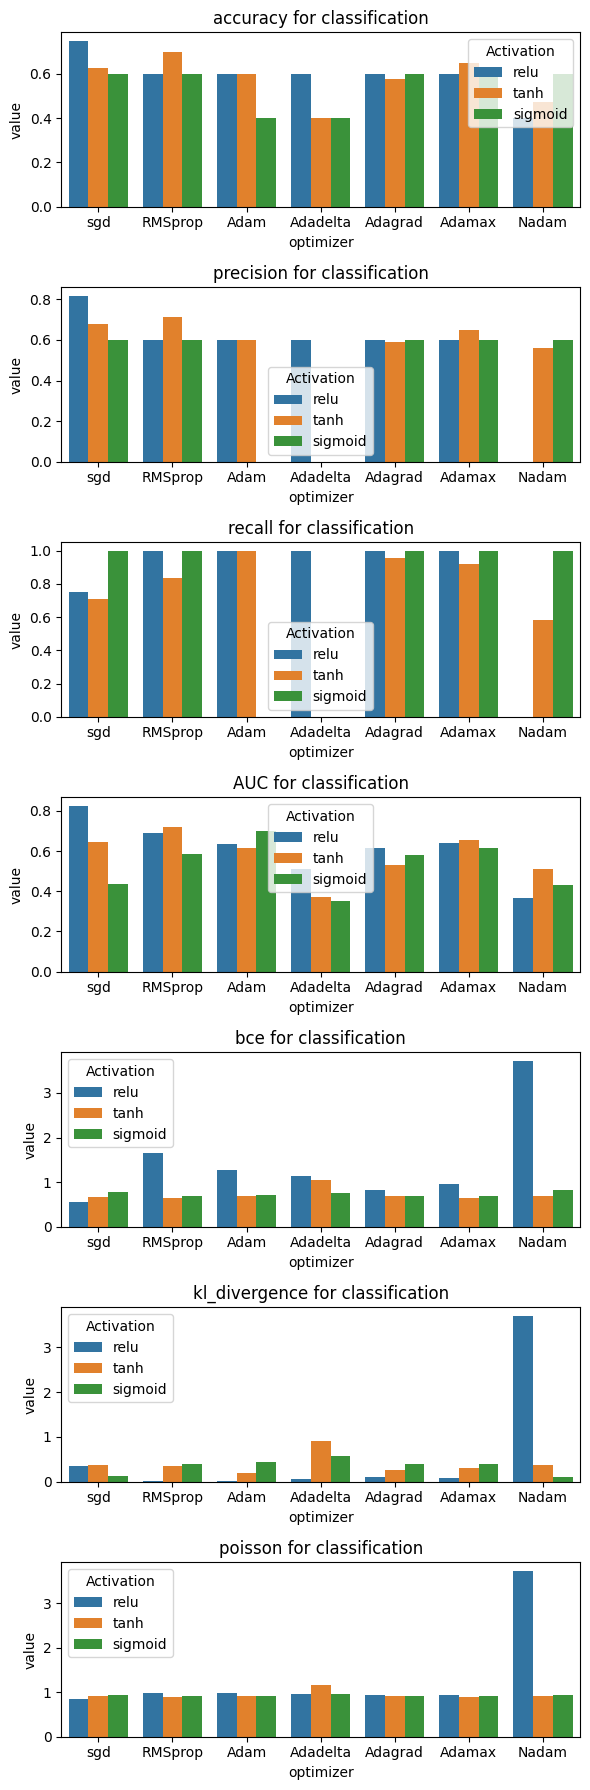

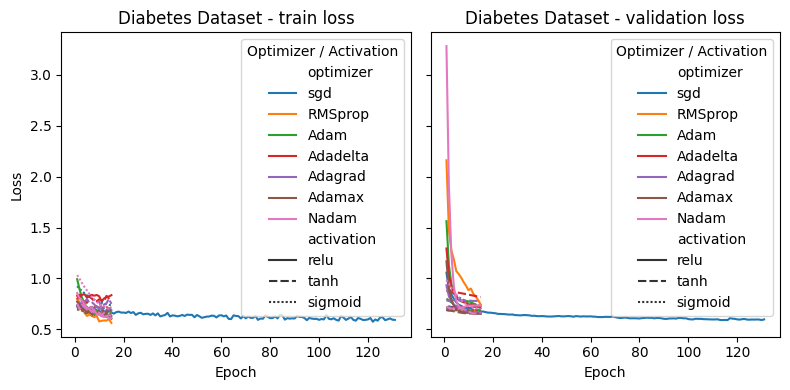

In [24]:
diabetes_title = "Diabetes Dataset"
diabetes_metrics, diabetes_mode, diabetes_history = pipeline(
    diabetes_df,
    target_column='diabetes',
    activations=activations,
    name=diabetes_title,
)

plot_metrics(diabetes_metrics, diabetes_mode)
plot_loss_curves(diabetes_history, diabetes_title)

Running the pipeline for Student Performance dataset...
steps_per_epoch=54


Evaluating models: 100%|██████████| 21/21 [00:06<00:00,  3.11it/s, optimizer=Nadam, activation=sigmoid]   


Plotting metrics for regression dataset...


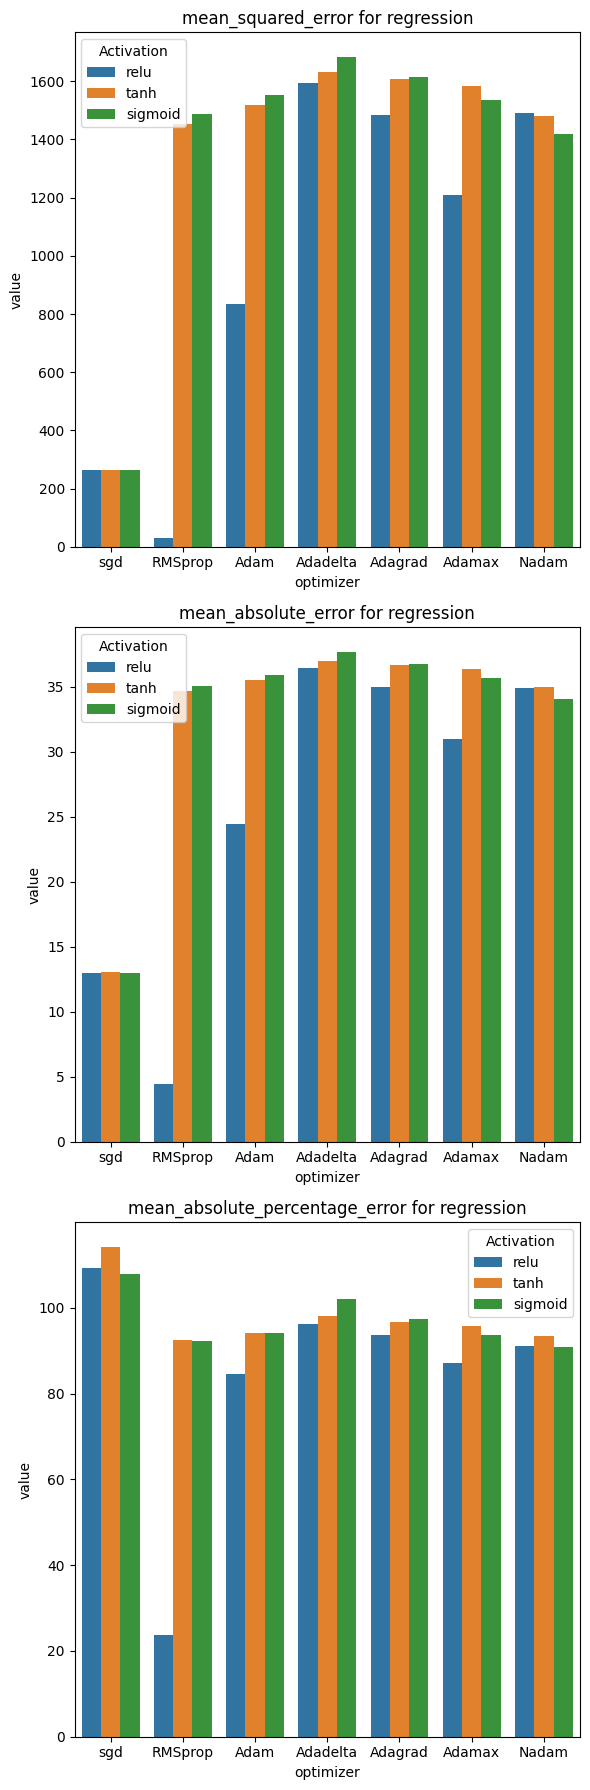

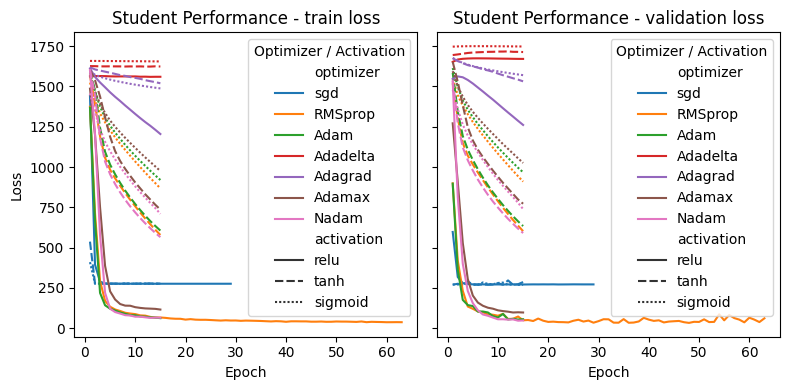

In [25]:
students_metrics, students_mode, students_history = pipeline(
    productivity_df,
    target_column='productivity_score',
    activations=activations,
    name="Student Performance",
)

plot_metrics(students_metrics, students_mode)
plot_loss_curves(students_history, "Student Performance")